# 05 · Regularized regression: ridge, lasso and elastic net

Notebooks 02-04 used a hand-picked, low-cardinality feature set. Here the design is opened up to the detailed
codes the government actually records: 4-character product/service codes, 6-digit NAICS industries, contracting
office, and the most frequent vendors. That gives ~700 sparse columns, so an unpenalized fit becomes unstable
and regularization becomes necessary.

**Part A.** Will the ceiling grow? Compare unpenalized, ridge (L2), lasso (L1) and elastic-net logistic
regression, with penalties tuned by cross-validation on FY2013-2021 and evaluated on the FY2022-23 cohort.
(The *size* of growth was tried first as a continuous target. Every linear model, penalized or not, had test
R² < 0.01. How much a contract grows is barely predictable at signing, but *whether* it grows is.)

**Part B.** The FY2025 termination wave. Among awards still active on 1 October 2024, which ones were
terminated during FY2025? An L1-penalized logistic model picks out the features that separate them.

In [1]:
import sys; sys.path.append("..")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.features import load_awards, model_frame

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
df = model_frame(load_awards())
df["psc4"] = df["product_or_service_code"].fillna("none")
df["naics6"] = df["naics_code"].fillna("none")
df["vendor"] = df["recipient_parent_uei"].fillna(df["recipient_uei"]).fillna("none")

NUMERIC = ["log_ceiling", "log_planned_years", "log_offers", "offers_missing", "single_offer", "small_business",
           "commercial_item", "performance_based", "log_solicitation_days", "solicitation_missing", "september",
           "final_two_weeks", "base_fiscal_year"]
CATEG = ["pricing", "competition", "award_kind", "psc_group", "sub_agency", "office", "psc4", "naics6", "vendor"]

def make_encoder():
    # Rare levels (< 30 awards) are folded into one "infrequent" column per feature.
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), CATEG),
    ])

def clean(name):
    return name.replace("cat__", "").replace("num__", "")

train = df[df["base_fiscal_year"] <= 2021]
test = df[df["base_fiscal_year"] > 2021]
enc = make_encoder().fit(train)
Xtr, Xte = enc.transform(train), enc.transform(test)
ytr, yte = train["any_growth"].values, test["any_growth"].values
names = np.array([clean(n) for n in enc.get_feature_names_out()])
print(f"design: {Xtr.shape[0]:,} rows × {Xtr.shape[1]:,} columns ({Xtr.nnz / np.prod(Xtr.shape):.2%} non-zero)")

design: 49,061 rows × 727 columns (3.03% non-zero)


## Part A: unpenalized vs ridge vs lasso vs elastic net

`base_fiscal_year` is entered as a numeric trend (standardized) so the model can score an unseen cohort. Each
penalty strength C (smaller C = stronger penalty) is tuned by 5-fold CV on log loss.

In [2]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
Cs = np.logspace(-3, 1, 9)
specs = {
    "Unpenalized": (LogisticRegression(C=1e8, solver="lbfgs", max_iter=5000), None),
    "Ridge (L2)": (LogisticRegression(l1_ratio=0.0, solver="liblinear", max_iter=5000), {"C": Cs}),
    "Lasso (L1)": (LogisticRegression(l1_ratio=1.0, solver="liblinear", max_iter=5000), {"C": Cs}),
    "Elastic net": (LogisticRegression(solver="saga", max_iter=5000),
                    {"C": Cs[2:8], "l1_ratio": [0.2, 0.5, 0.8]}),
}
fitted, rows = {}, []
for name, (est, grid) in specs.items():
    m = GridSearchCV(est, grid, scoring="neg_log_loss", cv=cv, n_jobs=-1).fit(Xtr, ytr).best_estimator_ \
        if grid else est.fit(Xtr, ytr)
    fitted[name] = m
    p = m.predict_proba(Xte)[:, 1]
    rows.append({"model": name, "test ROC AUC": roc_auc_score(yte, p), "test log loss": log_loss(yte, p),
                 "non-zero coefs": int((np.abs(m.coef_) > 1e-8).sum()), "C": m.C,
                 "l1_ratio": m.l1_ratio if name == "Elastic net" else np.nan})
results = pd.DataFrame(rows).set_index("model")
results.round(4)

,test ROC AUC,test log loss,non-zero coefs,C,l1_ratio
model,,,,,
Unpenalized,0.7626,0.4975,727,1.000000e+08,NaN
Ridge (L2),0.7657,0.4923,727,3.162000e-01,NaN
Lasso (L1),0.7660,0.4928,618,1.000000e+00,NaN
Elastic net,0.7652,0.4933,660,1.000000e+00,0.5


### Lasso regularization path

How coefficients enter as the penalty is relaxed. Features that enter early and stay are the robust signals.
Features that enter late are mostly specific codes or vendors fitting noise.

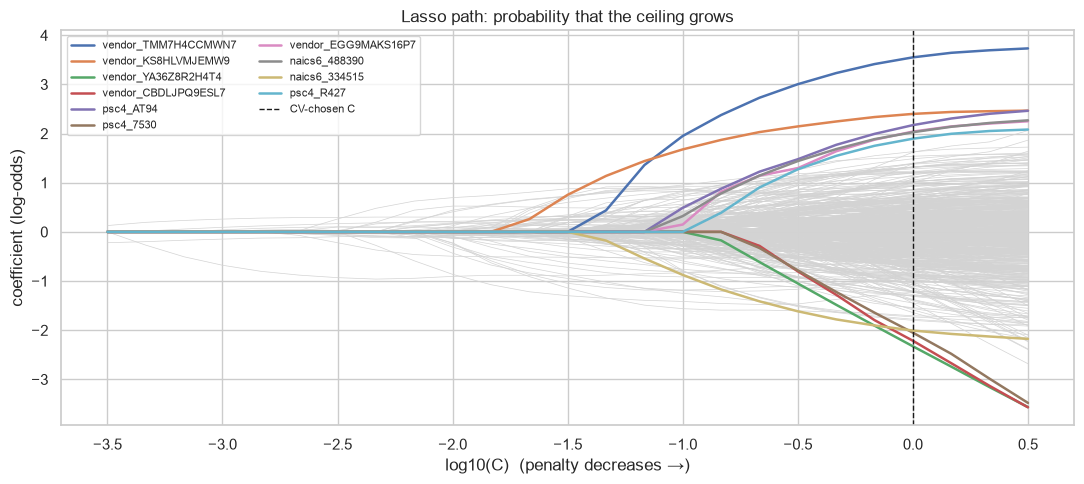

first 10 features to enter the lasso path:
log_ceiling                  C = 0.0003
pricing_firm_fixed           C = 0.0003
psc_group_products           C = 0.0005
log_planned_years            C = 0.0005
performance_based            C = 0.0010
small_business               C = 0.0010
offers_missing               C = 0.0015
log_offers                   C = 0.0022
award_kind_purchase_order    C = 0.0022
sub_agency_MARAD             C = 0.0022


In [3]:
path_Cs = np.logspace(-3.5, 0.5, 25)
path = np.array([LogisticRegression(l1_ratio=1.0, solver="liblinear", C=c, max_iter=5000).fit(Xtr, ytr).coef_.ravel()
                 for c in path_Cs])
lasso = fitted["Lasso (L1)"]
order = np.argsort(-np.abs(lasso.coef_.ravel()))[:10]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(np.log10(path_Cs), path, color="lightgrey", lw=0.5)
for i in order:
    ax.plot(np.log10(path_Cs), path[:, i], lw=1.8, label=names[i])
ax.axvline(np.log10(lasso.C), color="k", ls="--", lw=1, label="CV-chosen C")
ax.set(xlabel="log10(C)  (penalty decreases →)", ylabel="coefficient (log-odds)",
       title="Lasso path: probability that the ceiling grows")
ax.legend(fontsize=8, loc="upper left", ncol=2)
plt.tight_layout(); plt.savefig(FIG + "05_lasso_path.png", dpi=120); plt.show()

entered = pd.Series([path_Cs[np.argmax(np.abs(path[:, j]) > 1e-8)] if (np.abs(path[:, j]) > 1e-8).any() else np.nan
                     for j in range(path.shape[1])], index=names)
print("first 10 features to enter the lasso path:")
print(entered.dropna().sort_values().head(10).apply(lambda c: f"C = {c:.4f}").to_string())

In [4]:
def top_coefs(model, k=12):
    c = pd.Series(model.coef_.ravel(), index=names)
    c = c[c.abs() > 1e-8]
    return pd.concat([c.nlargest(k), c.nsmallest(k)]).to_frame("coef (log-odds)").round(3)

top_coefs(fitted["Elastic net"])

,coef (log-odds)
vendor_TMM7H4CCMWN7,3.265
vendor_KS8HLVMJEMW9,2.347
psc4_AT94,2.036
naics6_488390,1.907
vendor_EGG9MAKS16P7,1.884
psc4_R427,1.766
vendor_MU5BJR4UM2V3,1.551
vendor_NLNMLBJA3TF4,1.486
vendor_FYZWKUHGU8W4,1.477
vendor_NK7DHYALXVQ3,1.454


### Coefficient stability: lasso vs ridge on correlated codes

Product/service codes and NAICS codes overlap heavily (a 6-digit NAICS often maps to a handful of PSCs). Lasso
tends to keep one of a correlated pair and drop the other. Ridge spreads weight across both. Elastic net sits
between them. The plot compares coefficients for the 30 largest ridge features.

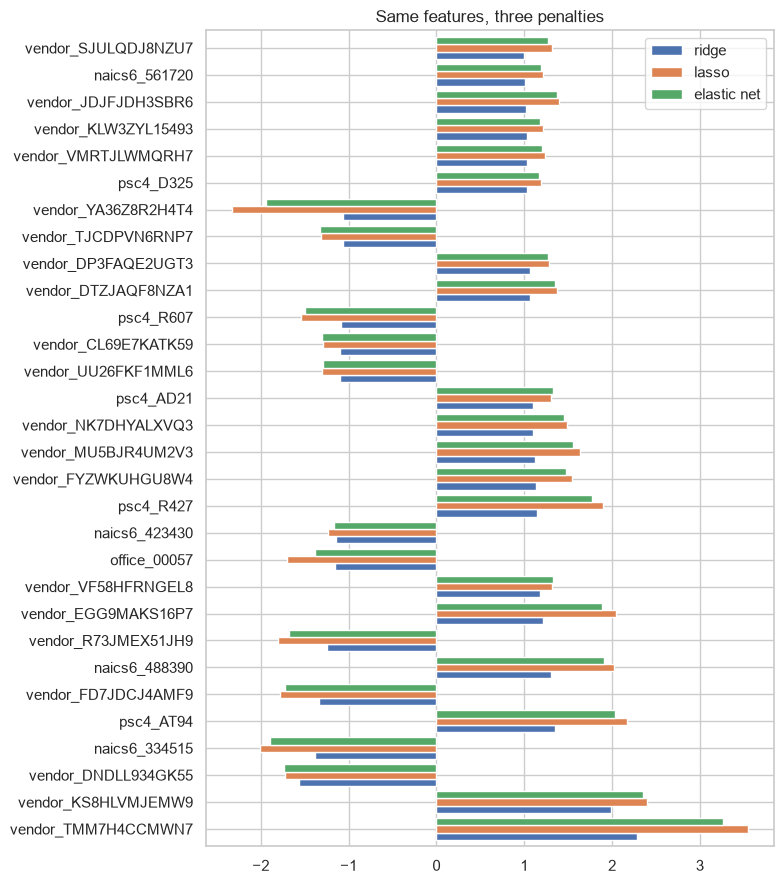

features zeroed by lasso among ridge's top 30: 0


In [5]:
ridge = fitted["Ridge (L2)"]
idx = np.argsort(-np.abs(ridge.coef_.ravel()))[:30]
cmp = pd.DataFrame({"ridge": ridge.coef_.ravel()[idx], "lasso": lasso.coef_.ravel()[idx],
                    "elastic net": fitted["Elastic net"].coef_.ravel()[idx]}, index=names[idx])
cmp.plot.barh(figsize=(8, 9), width=0.8)
plt.title("Same features, three penalties"); plt.tight_layout(); plt.savefig(FIG + "05_penalty_compare.png", dpi=120)
plt.show()
print(f"features zeroed by lasso among ridge's top 30: {(np.abs(cmp['lasso']) < 1e-8).sum()}")

## Part B: which contracts were cut in the FY2025 termination wave?

DOT terminations for convenience jumped from a typical 50-100 a year to over 400 in FY2025. Population: awards in
this dataset still active on 1 October 2024 (started before then, with work scheduled past that date).
Outcome: terminated during FY2025.

The positive class is rare, so evaluation uses average precision (area under the precision-recall curve)
alongside ROC AUC. The penalty is tuned inside each outer fold (nested cross-validation), so the reported scores
are not optimistic.

In [6]:
active = df[(df["start_date"] < "2024-10-01") & (df["final_end_date"] >= "2024-10-01")].copy()
fy25 = (active["termination_date"] >= "2024-10-01") & (active["termination_date"] <= "2025-09-30")
active["cut_fy25"] = fy25.astype(int)
print(f"active awards: {len(active):,}; terminated in FY2025: {active['cut_fy25'].sum()} "
      f"({active['cut_fy25'].mean():.2%})")

active awards: 4,660; terminated in FY2025: 128 (2.75%)


In [7]:
clf = GridSearchCV(
    make_pipeline(make_encoder(), LogisticRegression(l1_ratio=1.0, solver="liblinear", max_iter=5000)),
    {"logisticregression__C": np.logspace(-2, 1.5, 12)}, scoring="average_precision",
    cv=StratifiedKFold(5, shuffle=True, random_state=0), n_jobs=-1)
y = active["cut_fy25"].values
oof = cross_val_predict(clf, active, y, cv=StratifiedKFold(5, shuffle=True, random_state=1),
                        method="predict_proba")[:, 1]
print(f"out-of-fold ROC AUC = {roc_auc_score(y, oof):.3f}")
print(f"out-of-fold average precision = {average_precision_score(y, oof):.3f} (base rate {y.mean():.3f})")

clf.fit(active, y)
best = clf.best_estimator_
feat = [clean(n) for n in best[0].get_feature_names_out()]
coef = pd.Series(best[-1].coef_.ravel(), index=feat)
print(f"chosen C = {best[-1].C:.3g}; {int((coef != 0).sum())} of {len(coef)} features kept")

out-of-fold ROC AUC = 0.823
out-of-fold average precision = 0.157 (base rate 0.027)


chosen C = 15.2; 105 of 146 features kept


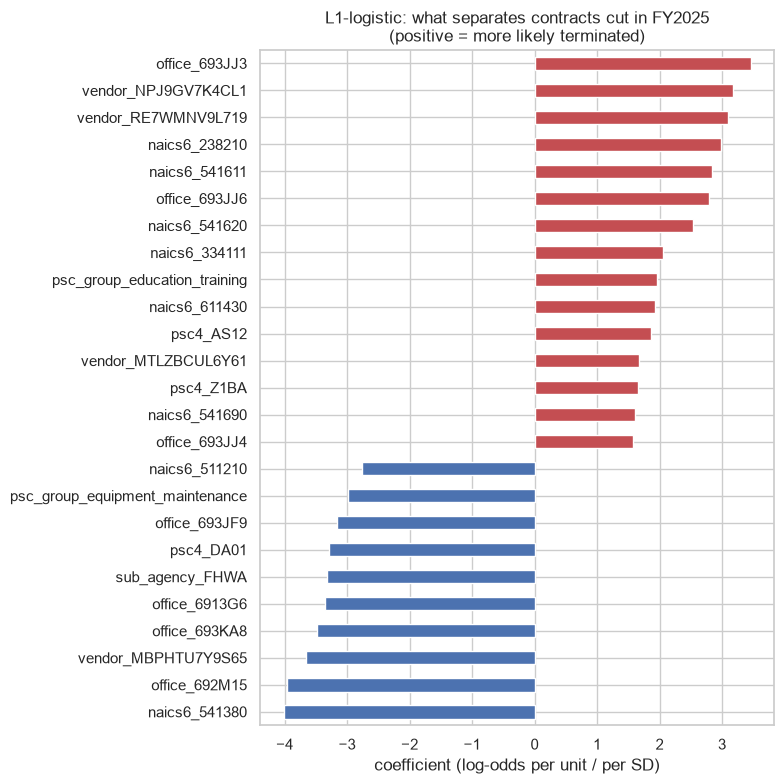

In [8]:
kept = coef[coef != 0].sort_values()
show = pd.concat([kept.head(10), kept.tail(15)])
show.plot.barh(figsize=(8, 8), color=np.where(show > 0, "C3", "C0"))
plt.title("L1-logistic: what separates contracts cut in FY2025\n(positive = more likely terminated)")
plt.xlabel("coefficient (log-odds per unit / per SD)")
plt.tight_layout(); plt.savefig(FIG + "05_fy25_terminations.png", dpi=120); plt.show()

In [9]:
# Plain-language view of the strongest categorical signals: termination rate by group.
for col in ["psc_group", "sub_agency", "pricing"]:
    t = active.groupby(col)["cut_fy25"].agg(["mean", "sum", "size"]).sort_values("mean", ascending=False)
    display(t.rename(columns={"mean": "share cut", "sum": "cut", "size": "active"}).round(3))

,share cut,cut,active
psc_group,,,
education_training,0.105,14,133
research,0.042,21,497
other_services,0.031,19,610
professional_services,0.031,45,1465
products,0.020,15,748
it_services,0.018,6,336
utilities_housekeeping,0.016,4,255
studies,0.015,1,66
construction,0.014,2,147


,share cut,cut,active
sub_agency,,,
other,0.117,31,264
OST,0.062,16,259
NHTSA,0.031,13,421
FHWA,0.022,20,918
FTA,0.019,4,211
FAA,0.018,42,2327
MARAD,0.008,2,260


,share cut,cut,active
pricing,,,
firm_fixed,0.028,90,3177
time_materials,0.027,28,1037
cost_reimbursement,0.024,10,420
fixed_other,0.000,0,26


## Findings

- **Regularization helps a little; detailed codes help more.** On the held-out FY2022-23 cohort, ridge and lasso
  improve log loss over the unpenalized fit (0.492 vs 0.498) and AUC (0.766 vs 0.763), and lasso does it with 109
  fewer columns. With ~49k training rows the unpenalized model is not badly overfit, so the gain is modest. The
  bigger jump comes from the detailed codes themselves. The same logistic model on the coarse feature set
  (notebook 08) reaches AUC 0.736.
- **The lasso path ranks the signals.** Size, pricing type, products vs services and planned length enter first.
  Specific vendors and 4-digit service codes enter late. They carry real signal (the largest elastic-net
  coefficients are individual vendors) but need the penalty to stay stable.
- **Vendor identity is predictive.** Some contractors' awards grow far more, or far less, than their contract
  terms would suggest. A vendor's track record is a feature a contracting officer could check at award time.
- **FY2025 terminations were predictable from award-time features.** Nested CV gives ROC AUC ≈ 0.82 and average
  precision 0.157, 5.7× the 2.7% base rate. Education/training (10.5% cut) and research (4.2%) contracts, and
  awards from the Office of the Secretary and the smaller administrations, were cut at several times the FAA's
  1.8%. Pricing type made no difference.